In [1]:
import sys, json, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import joblib
import matplotlib
import matplotlib.pyplot as plt
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))
from aqs import features as F, classify as K
from aqs.config import CITIES
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200, "display.max_columns", 30, "display.max_rows", 80)
OUT = ROOT / "outputs" / "model_comparison"
FIG = ROOT / "outputs" / "figures"
MODELS = OUT / "trained_models"
for p in (OUT, FIG, MODELS):
    p.mkdir(parents=True, exist_ok=True)
FAMILY_COLORS = {"Single": "#8a8984", "Bagging": "#2a78d6", "Boosting": "#eb6834", "Voting": "#1baf7a", "Stacking": "#6c4fd8"}
print(ROOT)

/home/claude/gurirath/aqi-vs-public-search-behaviour


In [2]:
data = K.build_dataset(F.load_long())
data.to_csv(ROOT / "data" / "processed" / "classification_dataset.csv", index=False)
summary = data.groupby(["split", "city"]).agg(weeks=("high", "size"), share_high=("high", "mean"), threshold=("threshold", "first"))
print(data.shape)
summary

(448, 31)


weeks  share_high  threshold
split city                                   
dev   bangkok       89    0.449438  21.907143
      krakow        70    0.485714  15.449167
      lahore        62    0.435484  93.542857
      melbourne     49    0.428571   5.605714
test  bangkok       51    0.529412  21.907143
      krakow        50    0.420000  15.449167
      lahore        41    0.487805  93.542857
      melbourne     36    0.500000   5.605714

In [3]:
zoo = K.model_zoo()
zoo_table = pd.DataFrame([(fam, name) for fam, name, _ in zoo], columns=["family", "model"])
zoo_table.to_csv(OUT / "model_zoo.csv", index=False)
print(len(zoo), "model configurations")
print(zoo_table["family"].value_counts().to_string())
print({k: len(v) for k, v in K.FEATURE_SETS.items()})

64 model configurations
family
Boosting    19
Single      15
Bagging     12
Stacking    10
Voting       8
{'calendar': 8, 'health': 8, 'search': 15, 'search+calendar': 19, 'all': 23}


In [4]:
t0 = time.time()
cv, cv_folds = K.cross_validate(data, zoo)
cv.to_csv(OUT / "cv_results.csv", index=False)
cv_folds.to_csv(OUT / "cv_folds.csv", index=False)
print(f"{len(cv)} model x feature-set runs in {time.time() - t0:.0f} s")

calendar: done


health: done


search: done


search+calendar: done


all: done
320 model x feature-set runs in 846 s


In [5]:
t0 = time.time()
test, test_preds, fitted = K.test_evaluate(data, zoo)
test.to_csv(OUT / "test_results.csv", index=False)
print(f"held-out 2024 evaluation in {time.time() - t0:.0f} s")

held-out 2024 evaluation in 245 s


In [6]:
board = cv.merge(test, on=["feature_set", "family", "model"])
board.to_csv(OUT / "leaderboard_all.csv", index=False)
cols = ["family", "model", "cv_accuracy", "cv_balanced_accuracy", "cv_auc", "test_accuracy", "test_balanced_accuracy", "test_f1", "test_auc"]
main = board[board["feature_set"] == "search+calendar"].sort_values("cv_balanced_accuracy", ascending=False)
main[cols].round(3).reset_index(drop=True)

,family,model,cv_accuracy,cv_balanced_accuracy,cv_auc,test_accuracy,test_balanced_accuracy,test_f1,test_auc
0,Bagging,"Extra trees (500, depth 6)",0.784,0.705,0.779,0.809,0.808,0.795,0.889
1,Single,SVM (RBF kernel),0.790,0.702,0.721,0.809,0.809,0.805,0.887
2,Bagging,Bagged SVM,0.766,0.697,0.728,0.815,0.815,0.811,0.891
3,Bagging,Extra trees (300),0.773,0.692,0.772,0.770,0.770,0.768,0.876
4,Stacking,"Stack: RF, ET, bagged trees → LR",0.746,0.691,0.750,0.798,0.797,0.788,0.881
5,Bagging,"Random forest (500, full depth)",0.746,0.682,0.716,0.764,0.763,0.753,0.862
6,Single,k-nearest neighbours (k=5),0.798,0.681,0.748,0.775,0.774,0.759,0.859
7,Voting,"Soft vote: RF, ET, HGB",0.752,0.674,0.725,0.787,0.785,0.768,0.857
8,Boosting,XGBoost random forest,0.743,0.671,0.671,0.775,0.776,0.773,0.855
9,Bagging,Bagged decision trees,0.737,0.671,0.688,0.775,0.775,0.770,0.860


In [7]:
y_test = data.loc[data["split"] == "test", "high"].values
majority = float(max(y_test.mean(), 1 - y_test.mean()))
persist = data.loc[data["split"] == "test", "persist"].values
persist_acc = float((persist == y_test).mean())
selected = board.loc[board.groupby("feature_set")["cv_balanced_accuracy"].idxmax()].set_index("feature_set")
selected = selected.loc[list(K.FEATURE_SETS)]
selected["test_ci_low"], selected["test_ci_high"] = zip(*[K.bootstrap_ci(y_test, test_preds[(fs, m)][0]) for fs, m in zip(selected.index, selected["model"])])
selected.to_csv(OUT / "selected_per_feature_set.csv")
print(f"majority-class accuracy on 2024: {majority:.3f}")
print(f"persistence (last week's PM2.5 class) accuracy on 2024: {persist_acc:.3f}")
selected[["family", "model", "cv_balanced_accuracy", "test_accuracy", "test_ci_low", "test_ci_high", "test_balanced_accuracy", "test_auc"]].round(3)

majority-class accuracy on 2024: 0.517
persistence (last week's PM2.5 class) accuracy on 2024: 0.730


,family,model,cv_balanced_accuracy,test_accuracy,test_ci_low,test_ci_high,test_balanced_accuracy,test_auc
feature_set,,,,,,,,
calendar,Boosting,CatBoost (depth 4),0.723,0.792,0.730,0.848,0.792,0.866
health,Single,k-nearest neighbours (k=5),0.583,0.522,0.449,0.596,0.517,0.505
search,Bagging,"Extra trees (500, depth 6)",0.691,0.730,0.669,0.792,0.725,0.831
search+calendar,Bagging,"Extra trees (500, depth 6)",0.705,0.809,0.753,0.865,0.808,0.889
all,Single,SVM (RBF kernel),0.721,0.809,0.747,0.860,0.808,0.882


In [8]:
ablation = board.groupby("feature_set").agg(models=("model", "size"), median_test_accuracy=("test_accuracy", "median"),
                                             best_test_accuracy=("test_accuracy", "max"), share_at_least_70=("test_accuracy", lambda s: (s >= 0.70).mean()),
                                             median_test_auc=("test_auc", "median")).loc[list(K.FEATURE_SETS)]
ablation.to_csv(OUT / "feature_set_ablation.csv")
ablation.round(3)

,models,median_test_accuracy,best_test_accuracy,share_at_least_70,median_test_auc
feature_set,,,,,
calendar,64,0.789,0.820,1.000,0.871
health,64,0.483,0.534,0.000,0.471
search,64,0.730,0.758,0.812,0.788
search+calendar,64,0.770,0.815,0.984,0.852
all,64,0.775,0.826,0.984,0.850


In [9]:
sel = selected.loc["search+calendar", "model"]
cal = selected.loc["calendar", "model"]
hl = selected.loc["health", "model"]
pred_sel = test_preds[("search+calendar", sel)][0]
tests = {
    f"search+calendar ({sel}) vs calendar only ({cal})": K.mcnemar(y_test, pred_sel, test_preds[("calendar", cal)][0]),
    f"search+calendar ({sel}) vs health only ({hl})": K.mcnemar(y_test, pred_sel, test_preds[("health", hl)][0]),
    f"search+calendar ({sel}) vs majority class": K.mcnemar(y_test, pred_sel, np.full_like(y_test, round(y_test.mean()))),
    f"search+calendar ({sel}) vs persistence": K.mcnemar(y_test, pred_sel, persist),
}
mcn = pd.DataFrame(tests).T
mcn.to_csv(OUT / "mcnemar_tests.csv")
mcn

,a_only_correct,b_only_correct,p
"search+calendar (Extra trees (500, depth 6)) vs calendar only (CatBoost (depth 4))",16.0,13.0,7.110711e-01
"search+calendar (Extra trees (500, depth 6)) vs health only (k-nearest neighbours (k=5))",65.0,14.0,5.194941e-09
"search+calendar (Extra trees (500, depth 6)) vs majority class",66.0,14.0,3.136543e-09
"search+calendar (Extra trees (500, depth 6)) vs persistence",26.0,12.0,3.355244e-02


In [10]:
fam = board[board["feature_set"] == "search+calendar"].groupby("family").agg(configs=("model", "size"),
        best_cv_bal_acc=("cv_balanced_accuracy", "max"), median_test_accuracy=("test_accuracy", "median"),
        best_test_accuracy=("test_accuracy", "max"), median_test_auc=("test_auc", "median"), mean_seconds=("seconds", "mean"))
fam = fam.loc[["Single", "Bagging", "Boosting", "Voting", "Stacking"]]
fam.to_csv(OUT / "family_summary.csv")
top10 = main["model"].head(10).tolist()
stat, p, ranks = K.friedman(cv_folds, "search+calendar", top10)
print(f"Friedman test across the top 10 configurations (4 development folds): chi2 = {stat:.2f}, p = {p:.3f}")
fam.round(3)

Friedman test across the top 10 configurations (4 development folds): chi2 = 10.30, p = 0.326


,configs,best_cv_bal_acc,median_test_accuracy,best_test_accuracy,median_test_auc,mean_seconds
family,,,,,,
Single,15,0.702,0.764,0.809,0.852,0.344
Bagging,12,0.705,0.775,0.815,0.861,1.686
Boosting,19,0.671,0.758,0.781,0.823,0.784
Voting,8,0.674,0.772,0.798,0.854,2.375
Stacking,10,0.691,0.778,0.798,0.872,11.908


In [11]:
city_acc = K.per_city(data, pred_sel)
city_acc["calendar_only"] = K.per_city(data, test_preds[("calendar", cal)][0])["accuracy"]
city_acc.index = [CITIES[c]["name"] for c in city_acc.index]
city_acc.to_csv(OUT / "per_city_accuracy.csv")
city_acc.round(3)

,weeks,accuracy,share_high,calendar_only
Bangkok,51.0,0.863,0.529,0.824
Kraków,50.0,0.800,0.420,0.740
Lahore,41.0,0.878,0.488,0.902
Melbourne,36.0,0.667,0.500,0.694


In [12]:
imp = K.importance(fitted[("search+calendar", sel)], data, K.FEATURE_SETS["search+calendar"])
imp.to_csv(OUT / "permutation_importance.csv", index=False)
imp.round(4).head(12)

,feature,mean,sd
11,month_sin,0.0472,0.0105
14,woy_cos,0.0457,0.0168
13,woy_sin,0.0369,0.0109
17,city_melbourne,0.0240,0.0073
10,attn_share_up,0.0161,0.0126
12,month_cos,0.0125,0.0102
18,city_lahore,0.0101,0.0089
3,awareness_roll4,0.0085,0.0070
1,awareness_z_lag1,0.0074,0.0063
0,awareness_z,0.0048,0.0028


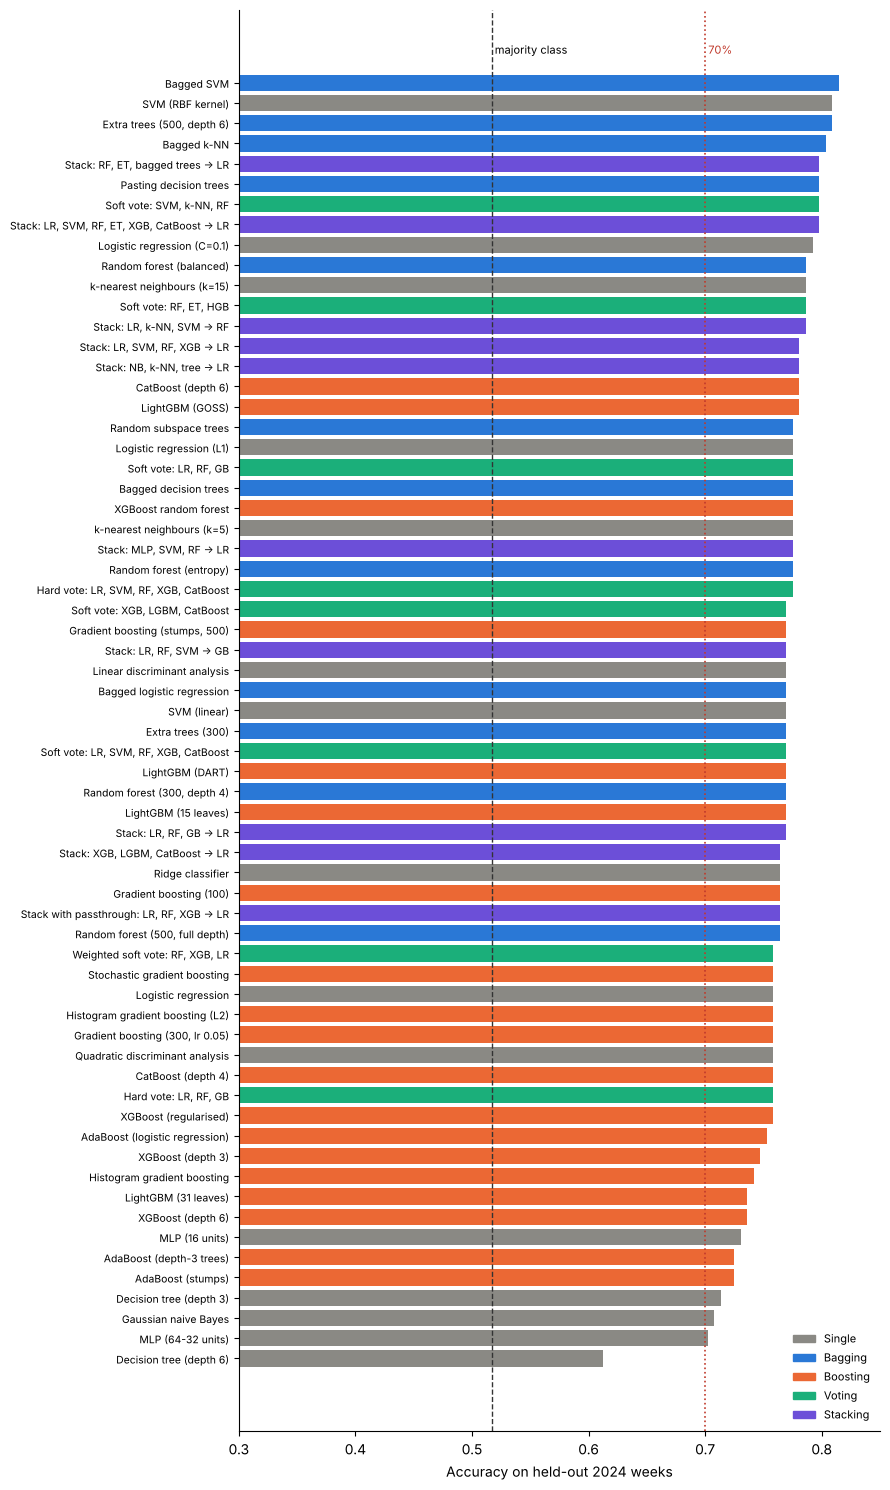

In [13]:
d = main.sort_values("test_accuracy")
fig, ax = plt.subplots(figsize=(9, 15))
ax.barh(range(len(d)), d["test_accuracy"], color=[FAMILY_COLORS[f] for f in d["family"]])
ax.set_yticks(range(len(d)), d["model"], fontsize=7.5)
ax.axvline(majority, color="#333", ls="--", lw=1)
ax.axvline(0.70, color="#c0392b", ls=":", lw=1.2)
ax.text(majority, len(d) + 0.3, " majority class", fontsize=8, va="bottom")
ax.text(0.70, len(d) + 0.3, " 70%", fontsize=8, va="bottom", color="#c0392b")
ax.set_xlim(0.3, 0.85)
ax.set_xlabel("Accuracy on held-out 2024 weeks")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=c, label=f) for f, c in FAMILY_COLORS.items()], loc="lower right", fontsize=8, frameon=False)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIG / "models_leaderboard.png", dpi=200)
plt.show()

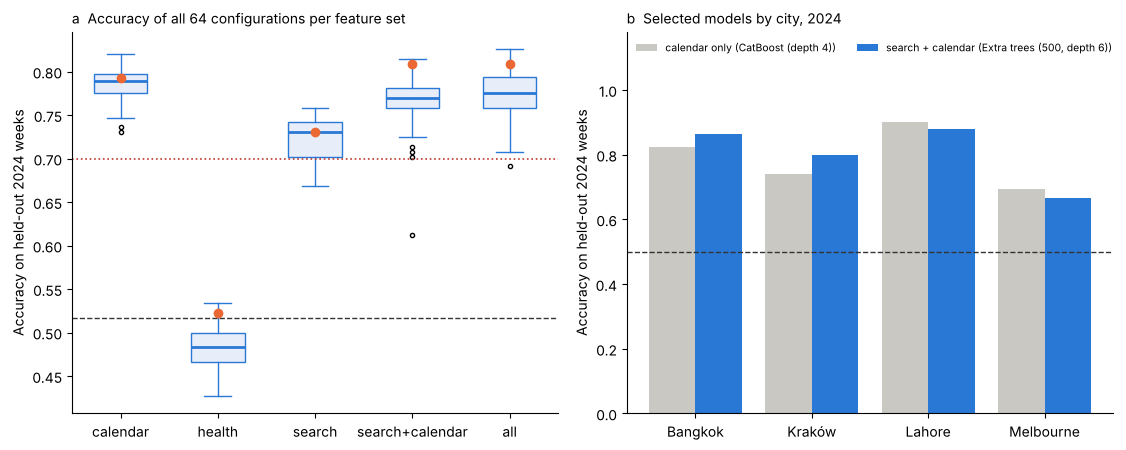

In [14]:
order = list(K.FEATURE_SETS)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
ax = axes[0]
for i, fs in enumerate(order):
    v = board.loc[board["feature_set"] == fs, "test_accuracy"]
    ax.boxplot(v, positions=[i], widths=0.55, patch_artist=True, boxprops=dict(facecolor="#e8eef9", color="#2a78d6"),
               medianprops=dict(color="#2a78d6", lw=2), whiskerprops=dict(color="#2a78d6"), capprops=dict(color="#2a78d6"), flierprops=dict(markersize=3))
    ax.scatter(i, selected.loc[fs, "test_accuracy"], color="#eb6834", zorder=3, s=36)
ax.axhline(majority, color="#333", ls="--", lw=1)
ax.axhline(0.70, color="#c0392b", ls=":", lw=1.2)
ax.set_xticks(range(len(order)), order)
ax.set_ylabel("Accuracy on held-out 2024 weeks")
ax.set_title("a  Accuracy of all 64 configurations per feature set", loc="left", fontsize=10)
ax.spines[["top", "right"]].set_visible(False)
ax = axes[1]
x = np.arange(len(city_acc))
ax.bar(x - 0.2, city_acc["calendar_only"], 0.4, color="#c9c8c2", label=f"calendar only ({cal})")
ax.bar(x + 0.2, city_acc["accuracy"], 0.4, color="#2a78d6", label=f"search + calendar ({sel})")
ax.axhline(0.5, color="#333", ls="--", lw=1)
ax.set_xticks(x, city_acc.index)
ax.set_ylim(0, 1.18)
ax.set_yticks(np.arange(0, 1.01, 0.2))
ax.set_ylabel("Accuracy on held-out 2024 weeks")
ax.set_title("b  Selected models by city, 2024", loc="left", fontsize=10)
ax.legend(fontsize=7.5, frameon=False, loc="upper left", ncol=2)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIG / "models_feature_sets_cities.png", dpi=200)
plt.show()

In [15]:
saved = []
keys = [(fs, selected.loc[fs, "model"]) for fs in K.FEATURE_SETS]
keys += [("search+calendar", m) for m in main.sort_values("test_accuracy", ascending=False)["model"].head(5)]
for fs, m in dict.fromkeys(keys):
    name = f"{fs}__{m}".replace(" ", "_").replace("/", "-").replace("→", "to").replace(",", "").replace("(", "").replace(")", "").replace(":", "").replace("=", "")
    joblib.dump({"model": fitted[(fs, m)], "features": K.FEATURE_SETS[fs], "feature_set": fs, "trained_on": "2022-2023 development weeks"}, MODELS / f"{name}.joblib")
    saved.append(name)
pd.Series(saved).to_csv(MODELS / "index.csv", index=False, header=["file"])
print(len(saved), "models saved to", MODELS)

9 models saved to /home/claude/gurirath/aqi-vs-public-search-behaviour/outputs/model_comparison/trained_models


In [16]:
best_test = main.sort_values("test_accuracy", ascending=False).iloc[0]
report = {
    "rows": int(len(data)), "dev_weeks": int((data["split"] == "dev").sum()), "test_weeks": int((data["split"] == "test").sum()),
    "configurations": len(zoo), "feature_sets": len(K.FEATURE_SETS), "runs": int(len(board)),
    "majority_accuracy": majority, "persistence_accuracy": persist_acc,
    "selected": selected[["model", "family", "cv_balanced_accuracy", "test_accuracy", "test_ci_low", "test_ci_high", "test_balanced_accuracy", "test_f1", "test_auc"]].reset_index().to_dict(orient="records"),
    "best_by_test_search_calendar": {"model": best_test["model"], "test_accuracy": float(best_test["test_accuracy"])},
    "share_configs_at_least_70": ablation["share_at_least_70"].to_dict(),
    "friedman": {"chi2": float(stat), "p": float(p)},
}
(OUT / "summary.json").write_text(json.dumps(report, indent=2, default=float))
print(json.dumps(report, indent=2, default=float))

{
  "rows": 448,
  "dev_weeks": 270,
  "test_weeks": 178,
  "configurations": 64,
  "feature_sets": 5,
  "runs": 320,
  "majority_accuracy": 0.5168539325842696,
  "persistence_accuracy": 0.7303370786516854,
  "selected": [
    {
      "feature_set": "calendar",
      "model": "CatBoost (depth 4)",
      "family": "Boosting",
      "cv_balanced_accuracy": 0.7226640345826979,
      "test_accuracy": 0.7921348314606742,
      "test_ci_low": 0.7303370786516854,
      "test_ci_high": 0.848314606741573,
      "test_balanced_accuracy": 0.7920879676440848,
      "test_f1": 0.7861271676300579,
      "test_auc": 0.8656471183013145
    },
    {
      "feature_set": "health",
      "model": "k-nearest neighbours (k=5)",
      "family": "Single",
      "cv_balanced_accuracy": 0.5828447500455005,
      "test_accuracy": 0.5224719101123596,
      "test_ci_low": 0.449438202247191,
      "test_ci_high": 0.5955056179775281,
      "test_balanced_accuracy": 0.5171890798786654,
      "test_f1": 0.42176870748